##Carregando os dados

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# importando todas as bibliotecas importantes para cálculo e criação de visualização gráfica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import plotly.express as px
from pandas.plotting import scatter_matrix
from sklearn import model_selection
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# importando o arquivo
df = pd.read_csv('/content/drive/My Drive/FATEC/PI5/StressLevelDataset_reduzido.csv', sep=',')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,anxiety_level,self_esteem,depression,headache,sleep_quality,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,11,2,2,2,3,3,2,3,2,3,3,2,3,3,2,1
1,15,8,15,5,1,3,1,2,2,1,4,1,5,1,4,5,5,2
2,12,18,14,2,2,2,2,3,2,2,3,3,2,2,3,2,2,1
3,16,12,15,4,1,4,2,2,2,2,4,1,4,1,4,4,5,2
4,16,28,7,2,5,3,2,4,3,4,3,1,2,1,5,0,5,1


##Informações

In [ ]:
# Dimensão
print("Dimensões:", df.shape)

# Resumo estatístico
display(df.describe().T)

# Distribuição das classes
print("Quantidade por classe:")
display(df['stress_level'].value_counts().sort_index())

Dimensões: (1100, 18)


,count,mean,std,min,25%,50%,75%,max
anxiety_level,1100.0,11.063636,6.117558,0.0,6.0,11.0,16.0,21.0
self_esteem,1100.0,17.777273,8.944599,0.0,11.0,19.0,26.0,30.0
depression,1100.0,12.555455,7.727008,0.0,6.0,12.0,19.0,27.0
headache,1100.0,2.508182,1.409356,0.0,1.0,3.0,3.0,5.0
sleep_quality,1100.0,2.660000,1.548383,0.0,1.0,2.5,4.0,5.0
noise_level,1100.0,2.649091,1.328127,0.0,2.0,3.0,3.0,5.0
living_conditions,1100.0,2.518182,1.119208,0.0,2.0,2.0,3.0,5.0
safety,1100.0,2.737273,1.406171,0.0,2.0,2.0,4.0,5.0
basic_needs,1100.0,2.772727,1.433761,0.0,2.0,3.0,4.0,5.0
academic_performance,1100.0,2.772727,1.414594,0.0,2.0,2.0,4.0,5.0


Quantidade por classe:


,count
stress_level,
0,373
1,358
2,369


##Visualização dos dados

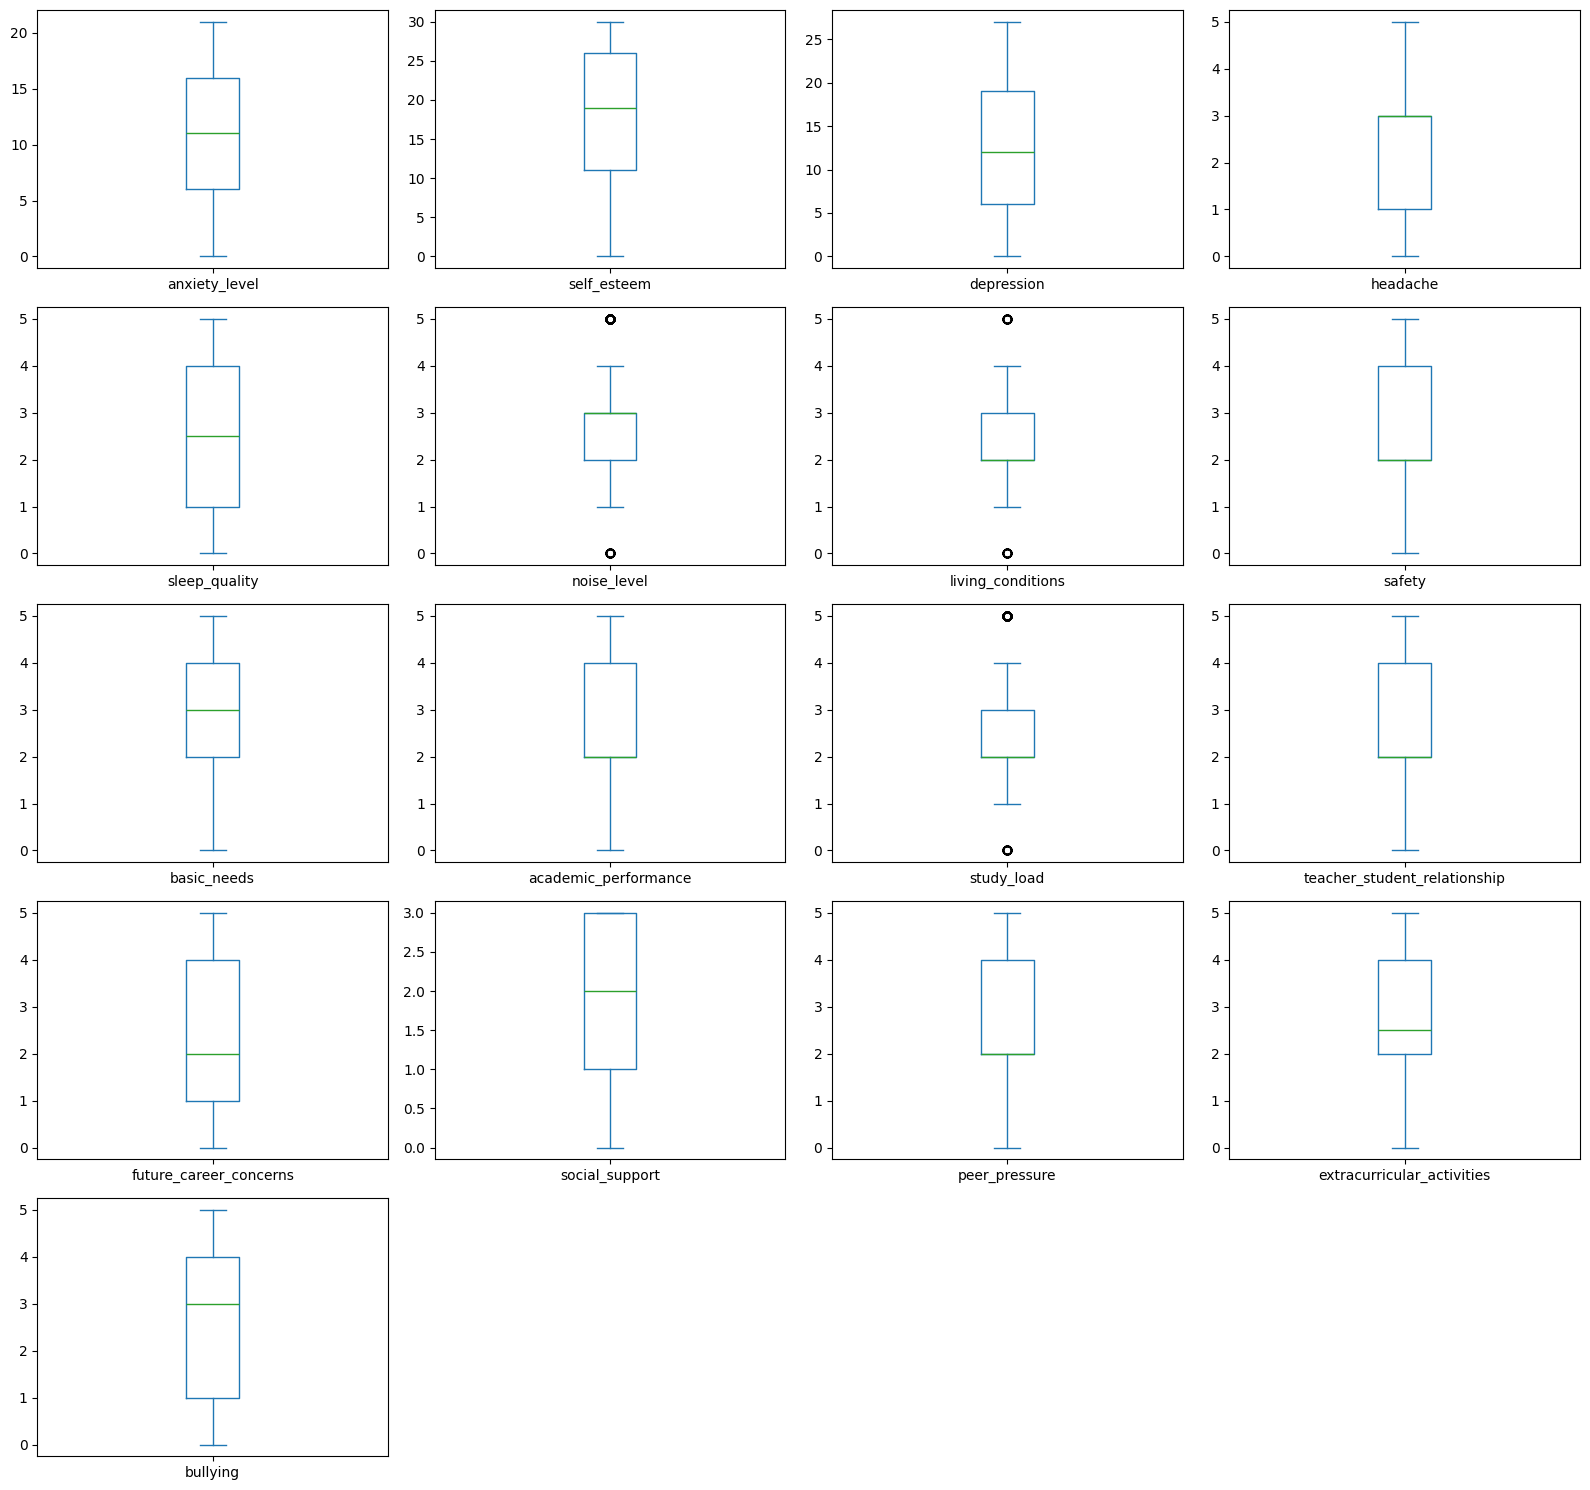

In [ ]:
# Somente as entradas
atributos = df.drop(columns=['stress_level'])

# Boxplots
atributos.plot(
    kind='box',
    subplots=True,
    layout=(5, 4),
    figsize=(16, 15),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

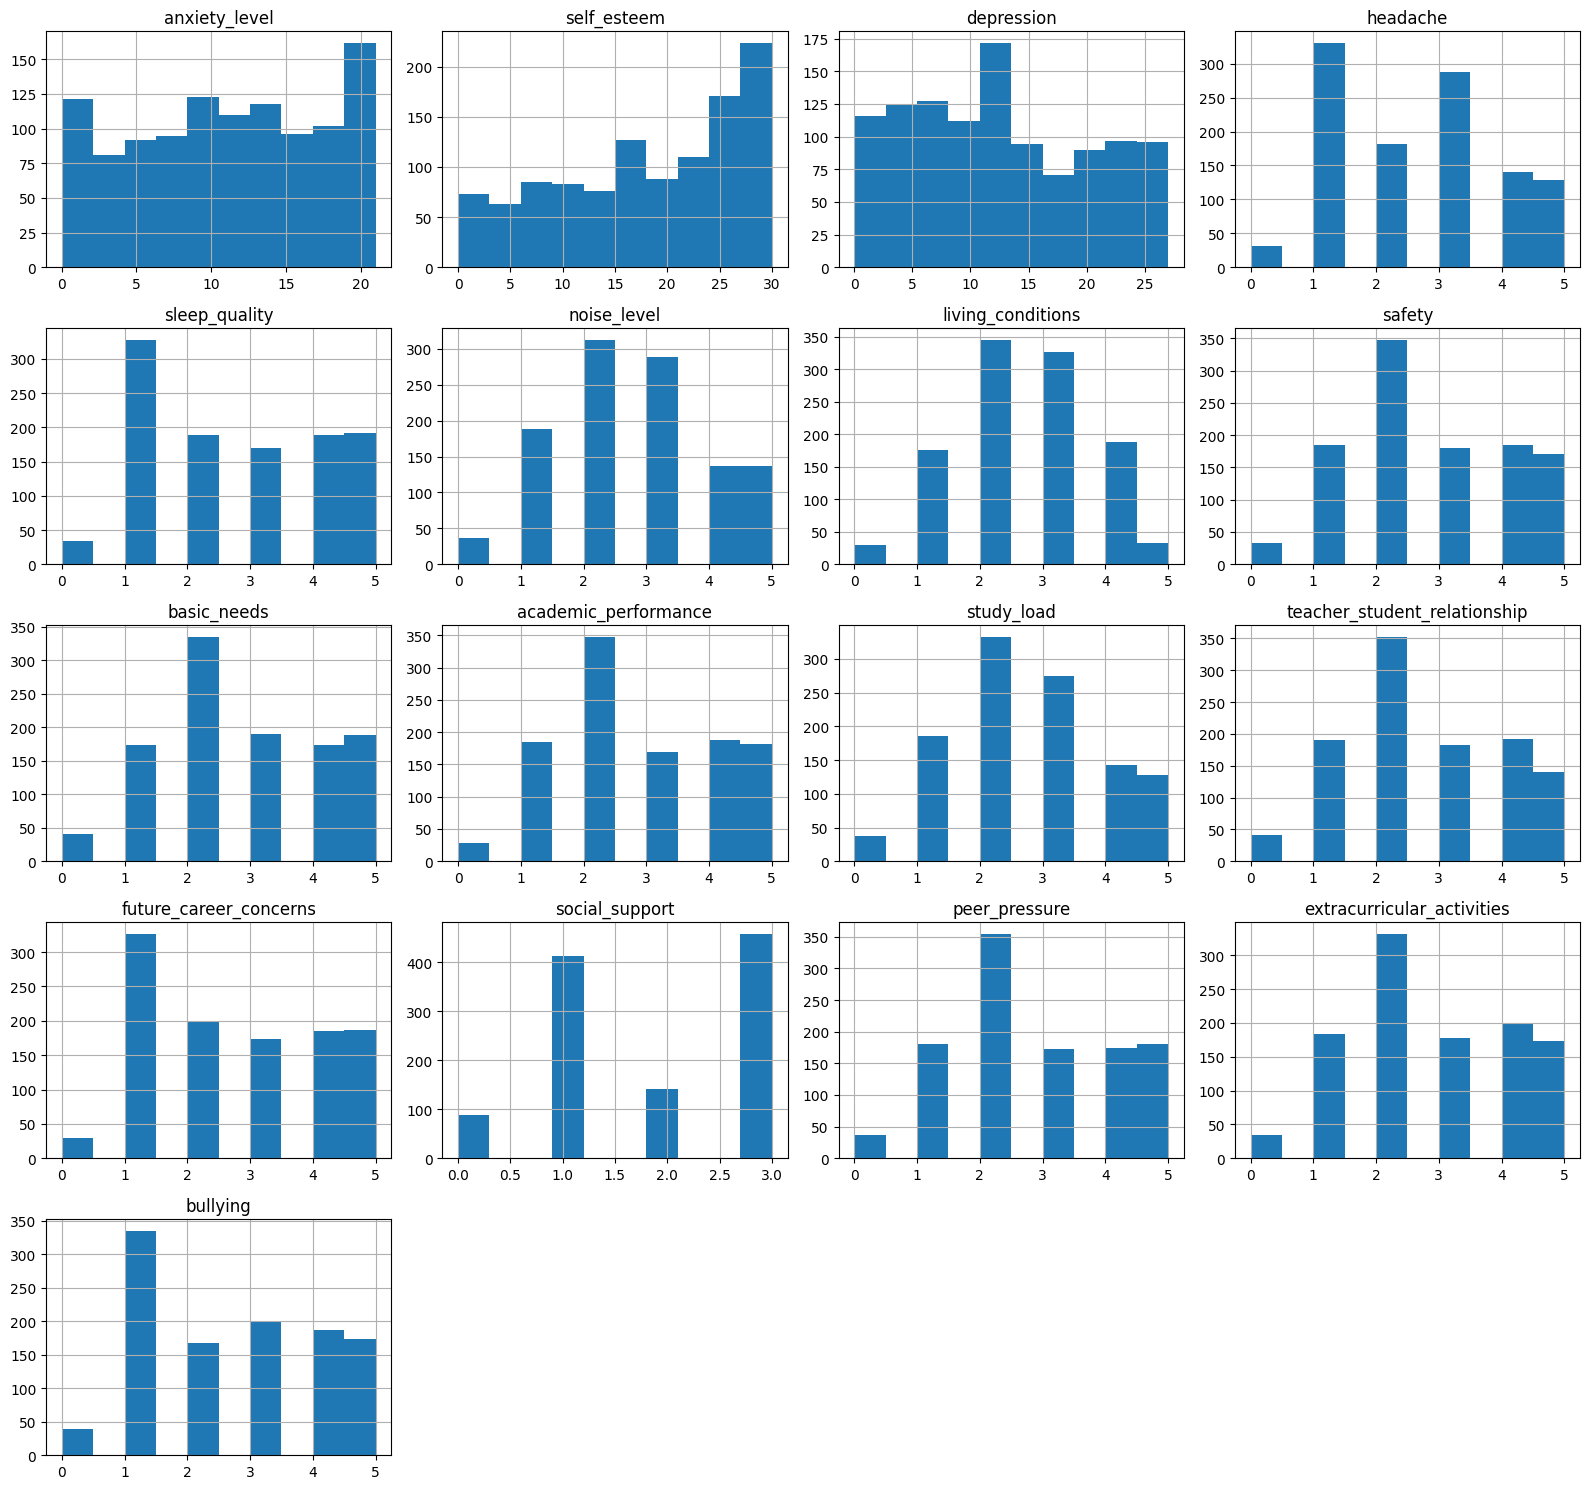

In [ ]:
# Histogramas
atributos.hist(
    figsize=(16, 15),
    layout=(5, 4),
    bins=10
)

plt.tight_layout()
plt.show()

##Criar conjunto de validação

In [ ]:
# Entradas e classificação
X = df.drop(columns=['stress_level'])
Y = df['stress_level']

validation_size = 0.20
seed = 7

X_train, X_validation, Y_train, Y_validation = (
    model_selection.train_test_split(
        X,
        Y,
        test_size=validation_size,
        random_state=seed,
        stratify=Y
    )
)

print("Entradas de treino:", X_train.shape)
print("Classes de treino:", Y_train.shape)

print("Entradas de validação:", X_validation.shape)
print("Classes de validação:", Y_validation.shape)


Entradas de treino: (880, 17)
Classes de treino: (880,)
Entradas de validação: (220, 17)
Classes de validação: (220,)


In [ ]:
# Métricas
seed = 7
scoring = 'accuracy'

### Regressão Logística (LR)
### Análise Linear Discriminante (LDA)
### K-vizinhos mais próximos (KNN)
### Árvores de Classificação (Decision Tree) e Regressão (CART)
### Gaussian Naive Bayes (NB)
### Support Vector Machines (SVM)

In [ ]:
# Bibliotecas para padronizar durante a avaliação
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Algoritmos
models = []
models.append(('LR', LogisticRegression(solver='lbfgs', max_iter=2000)))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('CART', DecisionTreeClassifier(random_state=seed)))
models.append(('NB', GaussianNB()))
models.append(('SVM', SVC(gamma='auto')))

# Avaliação de cada modelo
results = []
names = []

for name, model in models:
    kfold = model_selection.StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=seed
    )

    # Padronizando os dados para os algoritmos que se beneficiam disso
    if name in ['LR', 'LDA', 'KNN', 'SVM']:
        model = make_pipeline(StandardScaler(), model)

    cv_results = model_selection.cross_val_score(
        model, X_train, Y_train,
        cv=kfold,
        scoring=scoring
    )

    results.append(cv_results)
    names.append(name)

    msg = '%s: %f (%f)' % (
        name, cv_results.mean(), cv_results.std()
    )
    print(msg)

LR: 0.875000 (0.046577)
LDA: 0.873864 (0.031512)
KNN: 0.861364 (0.035136)
CART: 0.860227 (0.025435)
NB: 0.868182 (0.038770)
SVM: 0.875000 (0.044011)


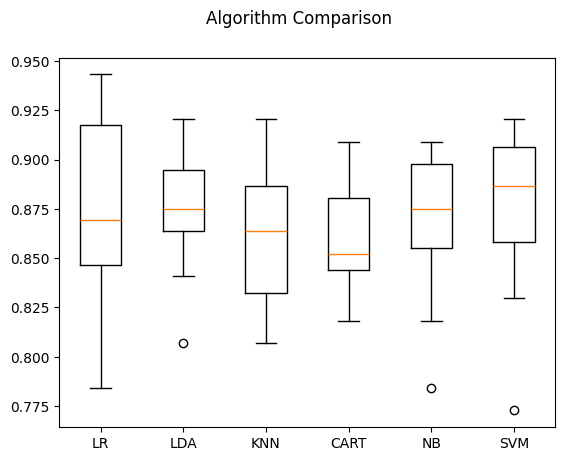

In [ ]:
# Comparação dos Algoritmos
fig = plt.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
plt.show()


##Fazer treinamento e validação de todos os algoritmos.

In [ ]:
# Acurácia do modelo no conjunto de treinamento
# SVM  — 880 registros

svc = make_pipeline(
    StandardScaler(),
    SVC(gamma='auto')
)

svc.fit(X_train, Y_train)

predictions = svc.predict(X_train)

print(accuracy_score(Y_train, predictions))
print(confusion_matrix(Y_train, predictions))
print(classification_report(Y_train, predictions))

0.9875
[[297   0   2]
 [  2 278   6]
 [  0   1 294]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       299
           1       1.00      0.97      0.98       286
           2       0.97      1.00      0.98       295

    accuracy                           0.99       880
   macro avg       0.99      0.99      0.99       880
weighted avg       0.99      0.99      0.99       880



In [ ]:
# Acurácia do SVM no conjunto de validação — 220 registros

predictions = svc.predict(X_validation)

print(accuracy_score(Y_validation, predictions))
print(confusion_matrix(Y_validation, predictions))
print(classification_report(Y_validation, predictions))

0.8954545454545455
[[67  0  7]
 [ 7 63  2]
 [ 6  1 67]]
              precision    recall  f1-score   support

           0       0.84      0.91      0.87        74
           1       0.98      0.88      0.93        72
           2       0.88      0.91      0.89        74

    accuracy                           0.90       220
   macro avg       0.90      0.90      0.90       220
weighted avg       0.90      0.90      0.90       220



In [ ]:
# Acurácia do NB no conjunto de treinamento — 880 registros
nb = GaussianNB()
nb.fit(X_train, Y_train)

predictions = nb.predict(X_train)

print(accuracy_score(Y_train, predictions))
print(confusion_matrix(Y_train, predictions))
print(classification_report(Y_train, predictions))

0.8829545454545454
[[258   8  33]
 [ 12 253  21]
 [ 17  12 266]]
              precision    recall  f1-score   support

           0       0.90      0.86      0.88       299
           1       0.93      0.88      0.91       286
           2       0.83      0.90      0.87       295

    accuracy                           0.88       880
   macro avg       0.89      0.88      0.88       880
weighted avg       0.89      0.88      0.88       880



In [ ]:
# Acurácia do NB no conjunto de validação — 220 registros
predictions = nb.predict(X_validation)

print(accuracy_score(Y_validation, predictions))
print(confusion_matrix(Y_validation, predictions))
print(classification_report(Y_validation, predictions))

0.9136363636363637
[[68  0  6]
 [ 2 63  7]
 [ 1  3 70]]
              precision    recall  f1-score   support

           0       0.96      0.92      0.94        74
           1       0.95      0.88      0.91        72
           2       0.84      0.95      0.89        74

    accuracy                           0.91       220
   macro avg       0.92      0.91      0.91       220
weighted avg       0.92      0.91      0.91       220



In [ ]:
# Acurácia da LR no conjunto de treinamento — 880 registros
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs', max_iter=2000)
)

lr.fit(X_train, Y_train)

predictions = lr.predict(X_train)

print(accuracy_score(Y_train, predictions))
print(confusion_matrix(Y_train, predictions))
print(classification_report(Y_train, predictions))

0.8886363636363637
[[261  18  20]
 [ 16 254  16]
 [ 16  12 267]]
              precision    recall  f1-score   support

           0       0.89      0.87      0.88       299
           1       0.89      0.89      0.89       286
           2       0.88      0.91      0.89       295

    accuracy                           0.89       880
   macro avg       0.89      0.89      0.89       880
weighted avg       0.89      0.89      0.89       880



In [ ]:
# Acurácia da LR no conjunto de validação — 220 registros
predictions = lr.predict(X_validation)

print(accuracy_score(Y_validation, predictions))
print(confusion_matrix(Y_validation, predictions))
print(classification_report(Y_validation, predictions))

0.9045454545454545
[[67  3  4]
 [ 5 62  5]
 [ 2  2 70]]
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        74
           1       0.93      0.86      0.89        72
           2       0.89      0.95      0.92        74

    accuracy                           0.90       220
   macro avg       0.91      0.90      0.90       220
weighted avg       0.91      0.90      0.90       220



In [ ]:
# Acurácia da LDA no conjunto de treinamento — 880 registros
lda = make_pipeline(
    StandardScaler(),
    LinearDiscriminantAnalysis()
)

lda.fit(X_train, Y_train)

predictions = lda.predict(X_train)

print(accuracy_score(Y_train, predictions))
print(confusion_matrix(Y_train, predictions))
print(classification_report(Y_train, predictions))

0.875
[[255  30  14]
 [ 11 259  16]
 [ 11  28 256]]
              precision    recall  f1-score   support

           0       0.92      0.85      0.89       299
           1       0.82      0.91      0.86       286
           2       0.90      0.87      0.88       295

    accuracy                           0.88       880
   macro avg       0.88      0.88      0.88       880
weighted avg       0.88      0.88      0.88       880



In [ ]:
# Acurácia da LDA no conjunto de validação — 220 registros
predictions = lda.predict(X_validation)

print(accuracy_score(Y_validation, predictions))
print(confusion_matrix(Y_validation, predictions))
print(classification_report(Y_validation, predictions))

0.8954545454545455
[[64  6  4]
 [ 3 64  5]
 [ 2  3 69]]
              precision    recall  f1-score   support

           0       0.93      0.86      0.90        74
           1       0.88      0.89      0.88        72
           2       0.88      0.93      0.91        74

    accuracy                           0.90       220
   macro avg       0.90      0.90      0.90       220
weighted avg       0.90      0.90      0.90       220



In [ ]:
# Acurácia do KNN no conjunto de treinamento — 880 registros
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

knn.fit(X_train, Y_train)

predictions = knn.predict(X_train)

print(accuracy_score(Y_train, predictions))
print(confusion_matrix(Y_train, predictions))
print(classification_report(Y_train, predictions))

0.8818181818181818
[[254  43   2]
 [  6 274   6]
 [ 14  33 248]]
              precision    recall  f1-score   support

           0       0.93      0.85      0.89       299
           1       0.78      0.96      0.86       286
           2       0.97      0.84      0.90       295

    accuracy                           0.88       880
   macro avg       0.89      0.88      0.88       880
weighted avg       0.89      0.88      0.88       880



In [ ]:
# Acurácia do KNN no conjunto de validação — 220 registros
predictions = knn.predict(X_validation)

print(accuracy_score(Y_validation, predictions))
print(confusion_matrix(Y_validation, predictions))
print(classification_report(Y_validation, predictions))

0.8818181818181818
[[61 13  0]
 [ 1 69  2]
 [ 1  9 64]]
              precision    recall  f1-score   support

           0       0.97      0.82      0.89        74
           1       0.76      0.96      0.85        72
           2       0.97      0.86      0.91        74

    accuracy                           0.88       220
   macro avg       0.90      0.88      0.88       220
weighted avg       0.90      0.88      0.88       220



In [ ]:
# Acurácia da CART no conjunto de treinamento — 880 registros
cart = DecisionTreeClassifier(random_state=seed)
cart.fit(X_train, Y_train)

predictions = cart.predict(X_train)

print(accuracy_score(Y_train, predictions))
print(confusion_matrix(Y_train, predictions))
print(classification_report(Y_train, predictions))

1.0
[[299   0   0]
 [  0 286   0]
 [  0   0 295]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       299
           1       1.00      1.00      1.00       286
           2       1.00      1.00      1.00       295

    accuracy                           1.00       880
   macro avg       1.00      1.00      1.00       880
weighted avg       1.00      1.00      1.00       880



In [ ]:
# Acurácia da CART no conjunto de validação — 220 registros
predictions = cart.predict(X_validation)

print(accuracy_score(Y_validation, predictions))
print(confusion_matrix(Y_validation, predictions))
print(classification_report(Y_validation, predictions))

0.8772727272727273
[[65  4  5]
 [ 5 63  4]
 [ 3  6 65]]
              precision    recall  f1-score   support

           0       0.89      0.88      0.88        74
           1       0.86      0.88      0.87        72
           2       0.88      0.88      0.88        74

    accuracy                           0.88       220
   macro avg       0.88      0.88      0.88       220
weighted avg       0.88      0.88      0.88       220



In [49]:
import joblib
from pathlib import Path

# Pasta de destino
pasta = Path('/content/drive/MyDrive/FATEC/PI5')
pasta.mkdir(parents=True, exist_ok=True)

# Pacote com o modelo treinado e a ordem dos atributos
pacote = {
    'modelo': lr,
    'colunas': X_train.columns.tolist()
}

# Salvando o modelo
arquivo = pasta / 'modelo_estresse_LR.joblib'

joblib.dump(pacote, arquivo)

print(f'Modelo salvo em: {arquivo}')
print(f'Atributos utilizados: {len(pacote["colunas"])}')

Modelo salvo em: /content/drive/MyDrive/FATEC/PI5/modelo_estresse_LR.joblib
Atributos utilizados: 17
